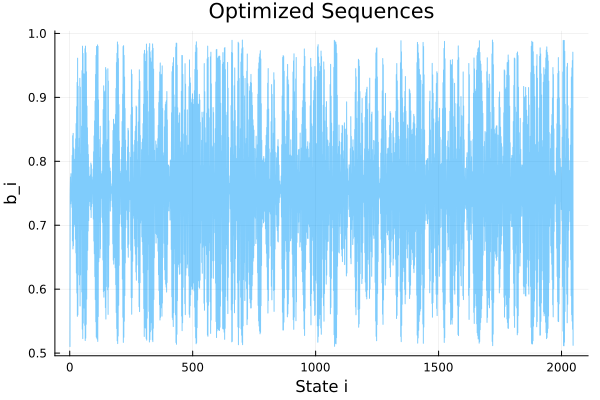

In [56]:
using DelimitedFiles
using Plots

# Update filename to match what was generated
filename = "data/optimal_sequences_N2048_M250_above_half.csv"

# Load the matrix (M rows, N-1 columns)
all_realizations = readdlm(filename, ',', Float64)
p = plot(legend=false, xlabel="State i", ylabel="b_i", title="Optimized Sequences")

# Example: Plot all realizations on the same figure
plot!(all_realizations[1, :], marker=:none, markersize=3, alpha=0.5)


display(p)

In [57]:
b_opt = all_realizations[1, :]

2047-element Vector{Float64}:
 0.5101353282486429
 0.7487953665168612
 0.7753311897645752
 0.7335530670422407
 0.7806456614444399
 0.7378008516192807
 0.7655667903283865
 0.7649828246518392
 0.7280182398064959
 0.8092147218563268
 0.6755591715644114
 0.8399765267963033
 0.6629216215684484
 ⋮
 0.8252869772939446
 0.6460816301299305
 0.8826209291329628
 0.5896384622161993
 0.9318582080738972
 0.560125290909523
 0.9460538917958439
 0.5500695371577001
 0.957655308484307
 0.5372987706075525
 0.9707213784549478
 0.5120791743996393

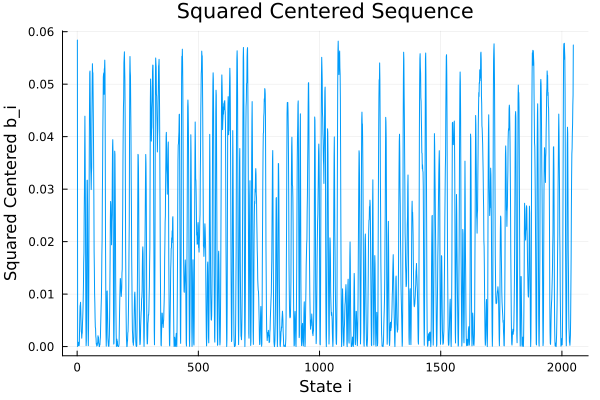

In [58]:
using Statistics

b_sq = (b_opt .- mean(b_opt)).^2

plot(b_sq, marker=:none, xlabel="State i", ylabel="Squared Centered b_i", legend=false, title="Squared Centered Sequence")

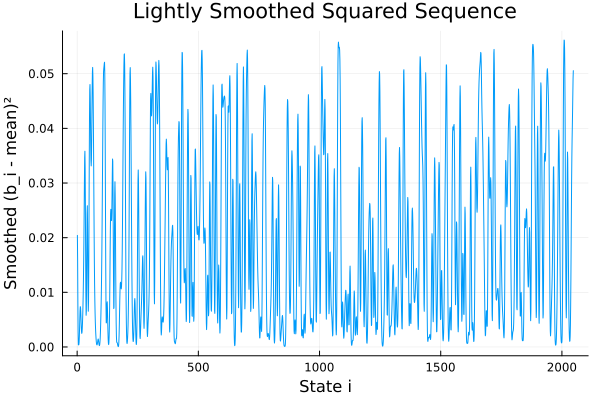

In [59]:
function smooth(iter, data)
    for _ in 1:iter
        data = [mean(data[max(1, i-1):min(end, i+1)]) for i in eachindex(data)]
    end
    return data
end

b_sm = smooth(3, b_sq)  # Apply smoothing 5 times

# Plot the smoothed squared data
plot(b_sm, marker=:none, xlabel="State i", ylabel="Smoothed (b_i - mean)²", legend=false, title="Lightly Smoothed Squared Sequence")

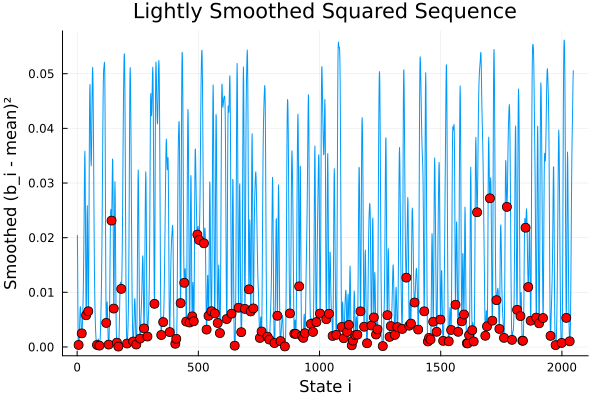

In [60]:
function detect_min(data, threshold)
    minima_indices = Int[]
    for i in 2:length(data)-1
        if data[i] < data[i-1] && data[i] < data[i+1] && data[i] < threshold*maximum(data)
            push!(minima_indices, i)
        end
    end
    return minima_indices
end

# Find the minima (make sure b_sm matches your variable name)
minima = detect_min(b_sm, 0.5)

# Plot the smoothed data line
plot(b_sm, xlabel="State i", ylabel="Smoothed (b_i - mean)²", legend=false, title="Lightly Smoothed Squared Sequence")

# Overlay the detected minima as red dots
scatter!(minima, b_sm[minima], color=:red, markersize=5)

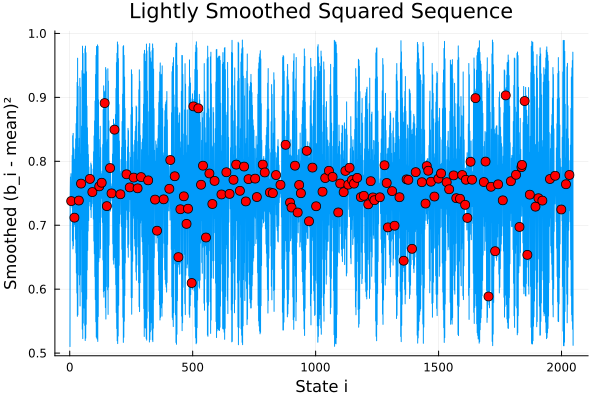

In [61]:
# Plot the smoothed data line
plot(b_opt, xlabel="State i", ylabel="Smoothed (b_i - mean)²", legend=false, title="Lightly Smoothed Squared Sequence")

# Overlay the detected minima as red dots
scatter!(minima, b_opt[minima], color=:red, markersize=5)

Fitted Gamma parameters: (4.739666973508778, 3.073393456932462)


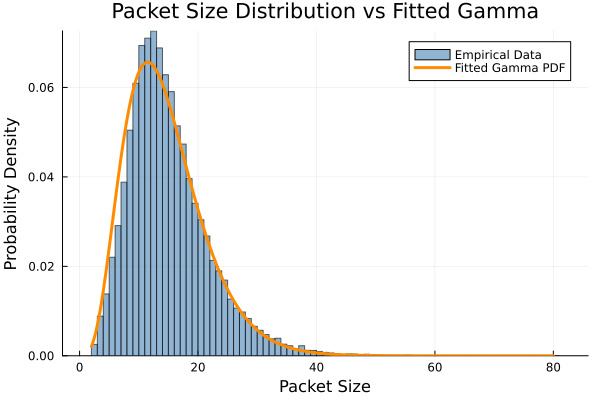

In [62]:
function packet_sizes(data; smooth_iters=3, threshold=0.5)
    all_sizes = Int[]
    
    for (i, realization) in enumerate(eachrow(data))
        # 1. Center the data
        centered = realization .- mean(realization)
        
        # 2. Square the data
        squared = centered.^2
        
        # 3. Smooth the data
        smoothed = smooth(smooth_iters, squared)
        
        # 4. Detect minima on the processed data
        minima = detect_min(smoothed, threshold)
        sizes = diff(minima)
        
        if isempty(sizes)
            # println("Realization $i: No packets found.")
        else
            append!(all_sizes, sizes)
            # println("Realization $i: Mean packet size = ", round(mean(sizes), digits=2), " (from ", length(sizes), " packets)")
        end
    end
    
    return all_sizes
end

# Extract the full list of sizes
all_packet_sizes = packet_sizes(all_realizations, smooth_iters=3, threshold=0.5)

using Distributions
using StatsPlots


# Fit a candidate distribution (e.g., Gamma approximation)
candidate_dist = fit(Gamma, Float64.(all_packet_sizes))

# Fit various discrete and continuous candidates
# Note: sizes must be converted to Float64 for continuous fits
dist_poisson = fit(Poisson, all_packet_sizes)
dist_geom = fit(Geometric, all_packet_sizes)
dist_gamma = fit(Gamma, Float64.(all_packet_sizes))
dist_lognorm = fit(LogNormal, Float64.(all_packet_sizes))

println("Fitted Gamma parameters: ", params(dist_gamma))

# Generate a Q-Q plot
qqplot(candidate_dist, Float64.(all_packet_sizes), 
    title="Q-Q Plot vs Gamma Distribution", 
    xlabel="Theoretical Quantiles", 
    ylabel="Empirical Quantiles",
    color=:steelblue)

# 1. Create a normalized histogram
overlay_plot = histogram(
    all_packet_sizes,
    normalize=:pdf, # Crucial: normalizes area to 1 to match the continuous PDF
    bins=maximum(all_packet_sizes) - minimum(all_packet_sizes) + 1,
    xlabel="Packet Size",
    ylabel="Probability Density",
    title="Packet Size Distribution vs Fitted Gamma",
    label="Empirical Data",
    color=:steelblue,
    alpha=0.6,
    grid=true
)

# 2. Generate a smooth x-axis range covering the data
x_range = range(minimum(all_packet_sizes), maximum(all_packet_sizes), length=500)

# 3. Plot the Gamma PDF over the histogram
plot!(
    overlay_plot,
    x_range,
    pdf.(dist_gamma, x_range),
    linewidth=3,
    color=:darkorange,
    label="Fitted Gamma PDF"
)

display(overlay_plot)

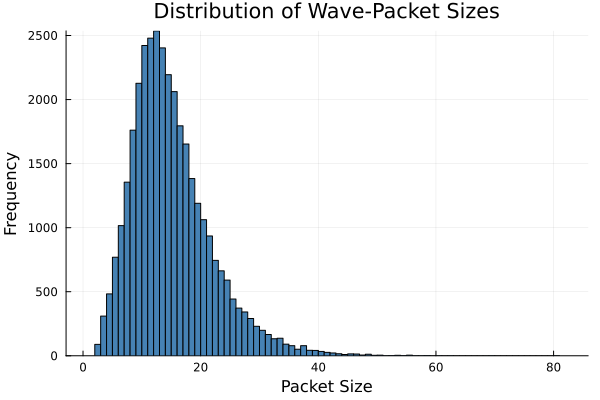

In [63]:
using Plots

# Plot the distribution of the collected packet sizes
histogram(
    all_packet_sizes,
    bins=maximum(all_packet_sizes) - minimum(all_packet_sizes) + 1,
    xlabel="Packet Size",
    ylabel="Frequency",
    title="Distribution of Wave-Packet Sizes",
    legend=false,
    grid=true,
    color=:steelblue
)

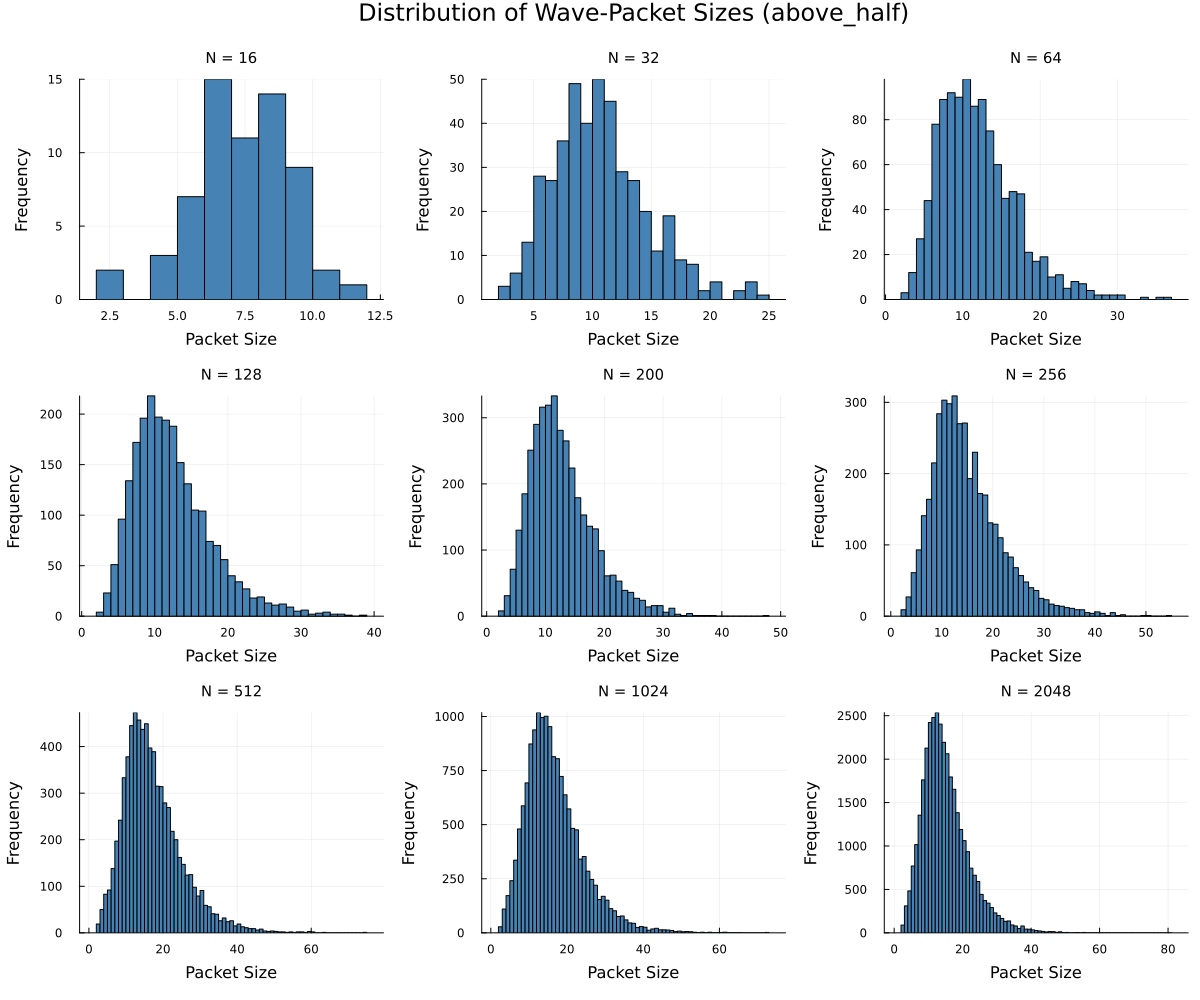

In [64]:
using DelimitedFiles
using Plots

N_values = [16, 32, 64, 128, 200, 256, 512, 1024, 2048]
M = 250
suffix = "above_half"
data_dir = joinpath(@__DIR__, "data")

# Array to store the individual histogram objects
histogram_plots = Any[]

for N in N_values
    filename = joinpath(data_dir, "optimal_sequences_N$(N)_M$(M)_$(suffix).csv")
    
    # Check if file exists to prevent errors if some N values haven't been generated
    if !isfile(filename)
        @warn "File not found: $filename"
        continue
    end
    
    data_matrix = readdlm(filename, ',', Float64)
    sizes = extract_packet_sizes(data_matrix, smooth_iters=3, threshold=0.5)

    if isempty(sizes)
        @warn "No packets extracted for N=$N"
        continue
    end

    # Determine bins based on the specific sizes for this N
    local_bins = maximum(sizes) - minimum(sizes) + 1

    p = histogram(
        sizes,
        bins=local_bins,
        xlabel="Packet Size",
        ylabel="Frequency",
        title="N = $N",
        titlefontsize=10,
        legend=false,
        grid=true,
        color=:steelblue,
        # xscale=:log10,
    )
    
    push!(histogram_plots, p)
end

# Combine all generated plots into a 3x3 grid
combined_histograms = plot(
    histogram_plots...,
    layout=(3, 3),
    size=(1200, 1000),
    plot_title="Distribution of Wave-Packet Sizes (above_half)",
    left_margin=4Plots.mm,
    bottom_margin=4Plots.mm
)

display(combined_histograms)
# savefig(combined_histograms, joinpath(@__DIR__, "all_N_histograms.pdf"))

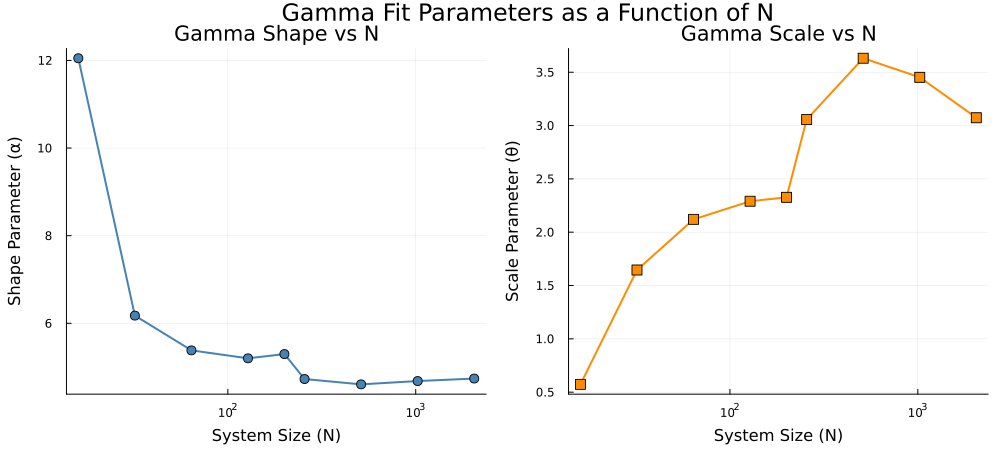

In [65]:
using DelimitedFiles
using Distributions
using Plots

N_values = [16, 32, 64, 128, 200, 256, 512, 1024, 2048]
M = 250
suffix = "above_half"
data_dir = joinpath(@__DIR__, "data")

valid_Ns = Int[]
shape_params = Float64[] # α
scale_params = Float64[] # θ

for N in N_values
    filename = joinpath(data_dir, "optimal_sequences_N$(N)_M$(M)_$(suffix).csv")
    
    if !isfile(filename)
        @warn "File not found for N=$N, skipping."
        continue
    end
    
    data_matrix = readdlm(filename, ',', Float64)
    
    # Assuming packet_sizes is defined as in your previous snippet
    sizes = packet_sizes(data_matrix, smooth_iters=3, threshold=0.5)
    
    # Robust filtering for continuous distribution fitting
    valid_sizes = filter(x -> !isnan(x) && !isinf(x) && x > 0, Float64.(sizes))
    
    if length(unique(valid_sizes)) > 1
        dist_gamma = fit(Gamma, valid_sizes)
        α, θ = params(dist_gamma)
        
        push!(valid_Ns, N)
        push!(shape_params, α)
        push!(scale_params, θ)
    else
        @warn "Not enough valid variance to fit Gamma for N=$N"
    end
end

# Plotting the parameters as a function of N
# Using a log10 scale for the x-axis since N spans two orders of magnitude
p_shape = plot(
    valid_Ns, shape_params,
    marker=:circle,
    markersize=5,
    linewidth=2,
    color=:steelblue,
    xlabel="System Size (N)",
    ylabel="Shape Parameter (α)",
    title="Gamma Shape vs N",
    xscale=:log10,
    legend=false,
    grid=true
)

p_scale = plot(
    valid_Ns, scale_params,
    marker=:square,
    markersize=5,
    linewidth=2,
    color=:darkorange,
    xlabel="System Size (N)",
    ylabel="Scale Parameter (θ)",
    title="Gamma Scale vs N",
    xscale=:log10,
    legend=false,
    grid=true
)

combined_plot = plot(
    p_shape, p_scale,
    layout=(1, 2),
    size=(1000, 450),
    plot_title="Gamma Fit Parameters as a Function of N",
    bottom_margin=5Plots.mm,
    left_margin=5Plots.mm
)

display(combined_plot)
# savefig(combined_plot, joinpath(@__DIR__, "gamma_parameters_vs_N.pdf"))

N=16: Found 107 packets. Mean=7.12, Var=2.9
N=32: Found 515 packets. Mean=9.57, Var=12.65
N=64: Found 1194 packets. Mean=10.78, Var=18.64
N=128: Found 2563 packets. Mean=11.24, Var=20.06
N=200: Found 4046 packets. Mean=11.62, Var=21.71
N=256: Found 4495 packets. Mean=13.54, Var=33.3
N=512: Found 8059 packets. Mean=15.47, Var=41.23
N=1024: Found 16804 packets. Mean=15.06, Var=38.08
N=2048: Found 37267 packets. Mean=13.66, Var=30.94


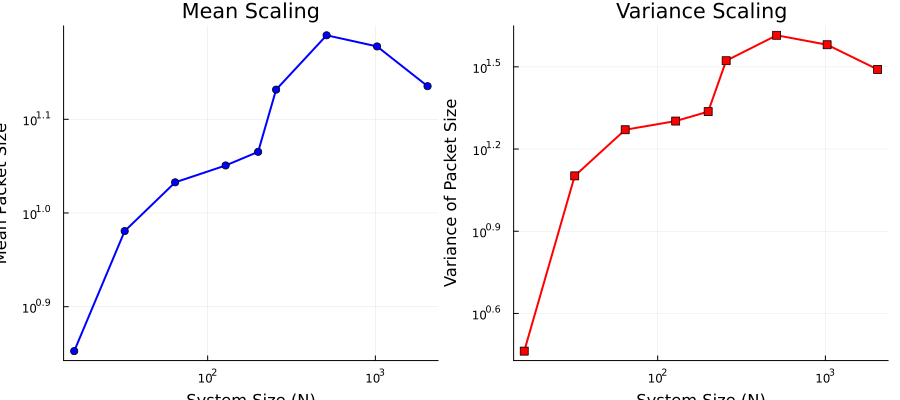

In [66]:
using DelimitedFiles
using Statistics
using Plots

# Define N values logarithmically spaced (powers of 2 are excellent for log-log plots)
N_values = [16, 32, 64, 128, 200, 256, 512, 1024, 2048]

# Adjust these parameters to match how you will generate your data
M = 250
suffix = "above_half"
data_dir = joinpath(@__DIR__, "data")

function smooth(iter, data)
    for _ in 1:iter
        data = [mean(data[max(1, i-1):min(end, i+1)]) for i in eachindex(data)]
    end
    return data
end

function detect_min(data, threshold)
    minima_indices = Int[]
    for i in 2:length(data)-1
        if data[i] < data[i-1] && data[i] < data[i+1] && data[i] < threshold
            push!(minima_indices, i)
        end
    end
    return minima_indices
end

function extract_packet_sizes(data_matrix; smooth_iters=3, threshold=0.5)
    all_sizes = Int[]
    for realization in eachrow(data_matrix)
        centered = realization .- mean(realization)
        squared = centered.^2
        smoothed = smooth(smooth_iters, squared)
        minima = detect_min(smoothed, threshold)
        sizes = diff(minima)
        
        if !isempty(sizes)
            append!(all_sizes, sizes)
        end
    end
    return all_sizes
end

# Storage for plotting
means = Float64[]
variances = Float64[]
valid_Ns = Int[]

# 1. Load data and calculate statistics
for N in N_values
    filename = joinpath(data_dir, "optimal_sequences_N$(N)_M$(M)_$(suffix).csv")
    
    if isfile(filename)
        data_matrix = readdlm(filename, ',', Float64)
        sizes = extract_packet_sizes(data_matrix, smooth_iters=3, threshold=0.5)
        
        if !isempty(sizes)
            push!(means, mean(sizes))
            push!(variances, var(sizes))
            push!(valid_Ns, N)
            println("N=$N: Found $(length(sizes)) packets. Mean=$(round(mean(sizes), digits=2)), Var=$(round(var(sizes), digits=2))")
        else
            println("N=$N: File found but no packets detected.")
        end
    else
        println("Missing file for N=$N, skipping... ($filename)")
    end
end

# 2. Plotting on a log-log scale
mean_plot = plot(
    valid_Ns, means, #./N_values[1:length(valid_Ns)],  # Normalize by the first N value
    xscale=:log10, yscale=:log10,
    marker=:circle, color=:blue, linewidth=2,
    xlabel="System Size (N)", ylabel="Mean Packet Size",
    title="Mean Scaling", legend=false, grid=true
)

variance_plot = plot(
    valid_Ns, variances, #./N_values[1:length(valid_Ns)],  # Normalize by the first N value
    xscale=:log10, yscale=:log10,
    marker=:square, color=:red, linewidth=2,
    xlabel="System Size (N)", ylabel="Variance of Packet Size",
    title="Variance Scaling", legend=false, grid=true
)

# Combine both plots side-by-side
combined_plot = plot(mean_plot, variance_plot, layout=(1, 2), size=(900, 400))
display(combined_plot)